# 12 — Financial Analytics

**FinRAG learning series · Notebook 12 of 14**

## Learning objectives
1. Compute revenue growth, net profit margin, operating profit margin, debt-to-equity, ROE and ROA with FinRAG's Python engine.
2. Verify a ratio by hand from the stored, cited inputs.
3. Understand when a ratio is **not** computed (missing inputs, failed validation, zero denominators) and why that matters.
4. Compare documents/periods and read compatibility warnings.
5. Visualise ratios and trends from real extracted data.

## Prerequisites
Notebooks 06–07. Processed documents in the app (saved outputs: two consecutive public annual reports).

## Concept
Ratios turn reported numbers into comparable measures. FinRAG computes them with `Decimal` arithmetic in
`financial_analytics/ratios.py`, only when **all inputs exist for the same document, basis, unit and fiscal year**, and none failed
validation. Income-statement columns ("2024-25") are aligned with the balance-sheet date of the same year ("As at 31st March, 2025").

| Ratio | Formula | Notes |
|---|---|---|
| Net profit margin | net profit / revenue × 100 | revenue = revenue from operations, else total revenue, else net sales (choice recorded) |
| Operating profit margin | operating profit / revenue × 100 | if not reported: PBT + finance costs − other income (derivation recorded) |
| Debt-to-equity | total debt / total equity | total debt = reported, else non-current + current borrowings (leases excluded) |
| ROE / ROA | net profit / closing equity (assets) × 100 | closing, not average, balances (warning recorded) |
| Growth | (current − previous) / |previous| × 100 | consecutive fiscal years in the same document/basis/unit |

In [1]:
# Setup: make the production backend importable and keep secrets out of outputs
import sys, os
sys.path.insert(0, os.path.abspath("."))      # run notebooks from the notebooks/ folder
import finrag_nb as nb                          # helper: paths, safe settings, DB session
print("Backend package:", nb.BACKEND_DIR)
print("Documents folder:", nb.DOCS_DIR)

Backend package: /home/user/Ready_To_Deploy/backend
Documents folder: /opt/finrag_testdocs


In [2]:
import pandas as pd
from app.models import Document
from app.financial_analytics import service
db = nb.db_session()
user = nb.notebook_user(db)
reports = db.query(Document).filter(Document.owner_id == user.id, Document.file_format == "pdf",
                                    Document.status == "processed", Document.page_count > 50).order_by(Document.fiscal_year).all()
print([(d.original_filename, d.fiscal_year) for d in reports])

[('RIL-Integrated-Annual-Report-2023-24.pdf', 'FY2023-24'), ('RIL-Integrated-Annual-Report-2024-25.pdf', 'FY2024-25')]


## 1. Ratios for the latest report

In [3]:
latest = reports[-1]
results = service.compute_ratios(db, user.id, [latest.id], persist=False)   # persist=False: read-only
df = pd.DataFrame(results)
print("status counts:", df.status.value_counts().to_dict())
ok = df[(df.status == "ok") & (df.basis == "consolidated")][["name", "period_label", "result", "result_unit", "formula"]]
ok

status counts: {'ok': 29, 'needs_verification': 20, 'insufficient_data': 16, 'invalid_input': 4}


,name,period_label,result,result_unit,formula
36,Net profit margin,2024-25,8.2957,percent,net profit / revenue × 100
39,Return on equity (closing equity),2024-25,8.0534,percent,net profit / total equity (closing) × 100
40,Return on assets (closing assets),2024-25,4.1694,percent,net profit / total assets (closing) × 100
41,Current ratio,2024-25,1.1004,times,total current assets / total current liabilities
42,Liabilities to assets,2024-25,48.2275,percent,total liabilities / total assets × 100
44,Expenses to revenue,2024-25,91.0177,percent,total expenses / revenue × 100
45,Net profit margin,2023-24,8.6411,percent,net profit / revenue × 100
48,Return on equity (closing equity),2023-24,8.5354,percent,net profit / total equity (closing) × 100
49,Return on assets (closing assets),2023-24,4.5000,percent,net profit / total assets (closing) × 100
50,Current ratio,2023-24,1.1830,times,total current assets / total current liabilities


## 2. Check one ratio by hand from its cited inputs

In [4]:
from decimal import Decimal
roe = next(r for r in results if r["calc_key"] == "return_on_equity" and r["basis"] == "consolidated" and r["status"] == "ok"
           and r["period_label"] == ok.period_label.iloc[0])
for i in roe["inputs"]:
    print(f"{i['key']:<14} {i['value']:>16}  {i['source']}  [{i['validation_status']}]")
np_, eq = (Decimal(i["value"]) for i in roe["inputs"])
print("by hand:", (np_ / eq * 100).quantize(Decimal("0.0001")), "% | engine:", roe["result"], "% | warnings:", roe["warnings"])

net_profit         81309.000000  page 100 (printed p. 196)  [validated]
total_equity     1009626.000000  page 99 (printed p. 195)  [validated]
by hand: 8.0534 % | engine: 8.0534 % | warnings: ["net profit input = 'net_profit'", 'uses closing equity of the same period, not average equity']


## 3. Why some ratios were not computed

In [5]:
nd = df[df.status != "ok"][["name", "basis", "period_label", "status", "missing"]]
print(len(nd), "ratio(s) not computed; examples:")
nd.head(8)

40 ratio(s) not computed; examples:


,name,basis,period_label,status,missing
0,Net profit margin,NaN,FY 2024-25,invalid_input,[]
1,Operating profit margin,NaN,FY 2024-25,insufficient_data,[operating profit]
2,Debt-to-equity,NaN,FY 2024-25,insufficient_data,"[total debt, total equity]"
3,Return on equity (closing equity),NaN,FY 2024-25,insufficient_data,[total equity]
4,Return on assets (closing assets),NaN,FY 2024-25,insufficient_data,[total assets]
5,Current ratio,NaN,FY 2024-25,insufficient_data,"[current assets, current liabilities]"
6,Liabilities to assets,NaN,FY 2024-25,insufficient_data,"[total liabilities, total assets]"
7,Interest coverage,NaN,FY 2024-25,insufficient_data,"[profit before tax, finance costs]"


A ratio that is *not* computed is a correct outcome: for example a summary table without equity cannot give ROE, and FinRAG will not
borrow equity from another table, basis or year to fill the gap.

## 4. Visualise: two years side by side

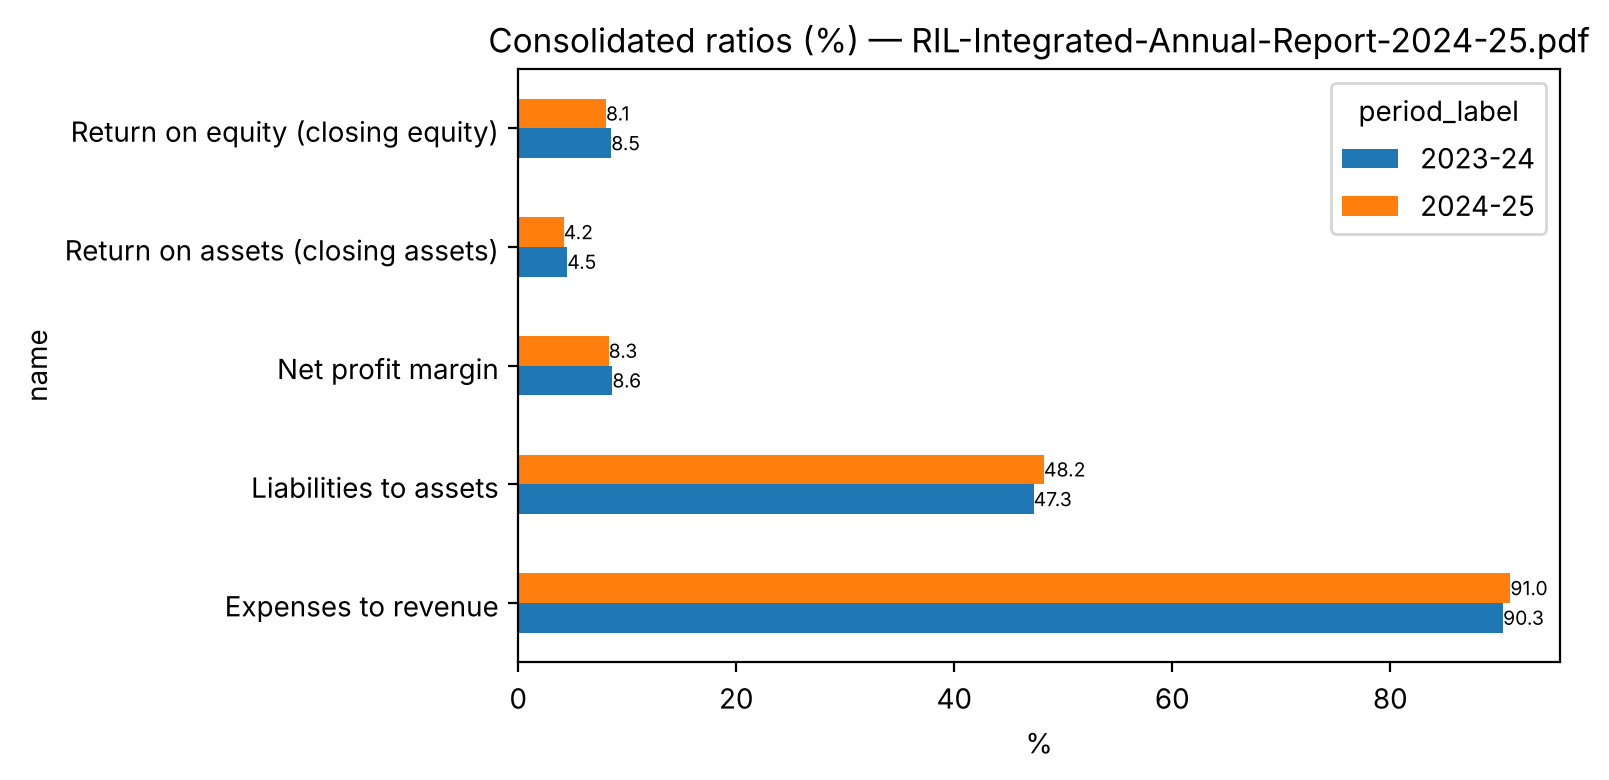

In [6]:
import matplotlib.pyplot as plt, numpy as np
cons = df[(df.status == "ok") & (df.basis == "consolidated") & (df.result_unit == "percent") & ~df.calc_key.str.endswith("_growth")]
piv = cons.pivot_table(index="name", columns="period_label", values="result", aggfunc="first").astype(float)
ax = piv.plot.barh(figsize=(8, 4))
ax.set_xlabel("%"); ax.set_title(f"Consolidated ratios (%) — {latest.original_filename}")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=7)
plt.tight_layout(); plt.show()

In [7]:
growth = df[df.calc_key.str.endswith("_growth")][["name", "basis", "period_label", "status", "result", "warnings"]]
growth

,name,basis,period_label,status,result,warnings
54,Revenue from operations growth,NaN,FY 2024-25,needs_verification,NaN,[not computed: unverified inputs: revenue_from...
55,Net profit growth,NaN,FY 2024-25,invalid_input,NaN,"[an input failed validation, was rejected or n..."
56,Profit before tax growth,NaN,FY 2024-25,invalid_input,NaN,"[an input failed validation, was rejected or n..."
57,Revenue from operations growth,standalone,2024-25,ok,-2.7649,[]
58,Total income growth,standalone,2024-25,ok,-1.9969,[]
59,Net profit growth,standalone,2024-25,needs_verification,NaN,[not computed: unverified inputs: net_profit (...
60,Profit before tax growth,standalone,2024-25,ok,-16.5451,[]
61,Total assets growth,standalone,2024-25,ok,6.5397,[]
62,Total equity growth,standalone,2024-25,ok,5.4341,[]
63,Revenue from operations growth,consolidated,2024-25,ok,7.1805,[]


> **What the first run of this notebook found (2026-11-24, 03:57 UTC).** The growth table then contained *Net profit growth
> −56.6%* for a column with **no detected basis** — computed from a highlights table where one "net profit" value (4.1) was
> really a US$-billion sub-column and another (69,648) was a *Profit for the year* row inside a balance-sheet note. Both values
> were already marked `needs_review`, but the ratio engine still used them. Two generic fixes followed: inputs that need review
> now **block** ratios and growth (status `invalid_input`, unlock by verifying the value), and a flow item printed under a
> point-in-time column ("As at …") is flagged `needs_review`.
>
> **Later change (end-to-end audit).** Ratios and growth now use **validated or verified inputs only**. An input that is merely
> `unvalidated` (extracted, but no accounting identity confirmed it) gives status `needs_verification`, and the warning names the
> inputs to verify. That is why operating margin and debt-to-equity no longer appear in section 1, and why the `needs_verification`
> rows appear here. Verifying the values in Document Analysis (a human decision, recorded with who and when) unlocks them.

## 5. Compare two reports

In [8]:
from app.financial_analytics.comparison import compare_documents
cmp = compare_documents(db, user.id, [d.id for d in reports[-2:]], ["revenue_from_operations", "net_profit", "total_assets"])
print("WARNINGS:")
for w in cmp["warnings"]:
    print(" -", w)
rows = [{"document": c["filename"][:40], "column": c["period_label"], "basis": c["basis"],
         **{k: v["raw_value"] for k, v in c["values"].items()}} for c in cmp["columns"] if c["basis"] == "consolidated"]
pd.DataFrame(rows)

WARNINGS:
 - Reporting basis differs (not detected, standalone, consolidated): consolidated and standalone figures are not directly comparable.
 - Point-in-time (balance sheet) and period (income statement) columns are both present; they are shown separately.


,document,column,basis,total_assets,net_profit,revenue_from_operations
0,RIL-Integrated-Annual-Report-2024-25.pdf,"As at 31st March, 2024",consolidated,"17,55,986","69,621",NaN
1,RIL-Integrated-Annual-Report-2024-25.pdf,2023-24,consolidated,NaN,"79,020","9,14,472"
2,RIL-Integrated-Annual-Report-2024-25.pdf,"As at 31st March, 2025",consolidated,"19,50,121","69,648",NaN
3,RIL-Integrated-Annual-Report-2024-25.pdf,2024-25,consolidated,NaN,"81,309","9,80,136"
4,RIL-Integrated-Annual-Report-2023-24.pdf,Consolidated 2022-23,consolidated,NaN,"74,088",NaN
5,RIL-Integrated-Annual-Report-2023-24.pdf,"As at 31st March, 2023",consolidated,"16,07,431","66,702",NaN
6,RIL-Integrated-Annual-Report-2023-24.pdf,2022-23,consolidated,NaN,"74,088","8,91,311"
7,RIL-Integrated-Annual-Report-2023-24.pdf,"As at 31st March, 2024",consolidated,"17,55,986","69,621",NaN
8,RIL-Integrated-Annual-Report-2023-24.pdf,2023-24,consolidated,NaN,"79,020","9,14,472"


The same fiscal year appears in both reports (as *current* year in one, *previous* year in the other). Matching values across documents
confirm consistent extraction; a different value would produce a *possible restatement* warning (only validated values with a known basis
are compared, to avoid false alarms).

## 6. Revenue trend across reports

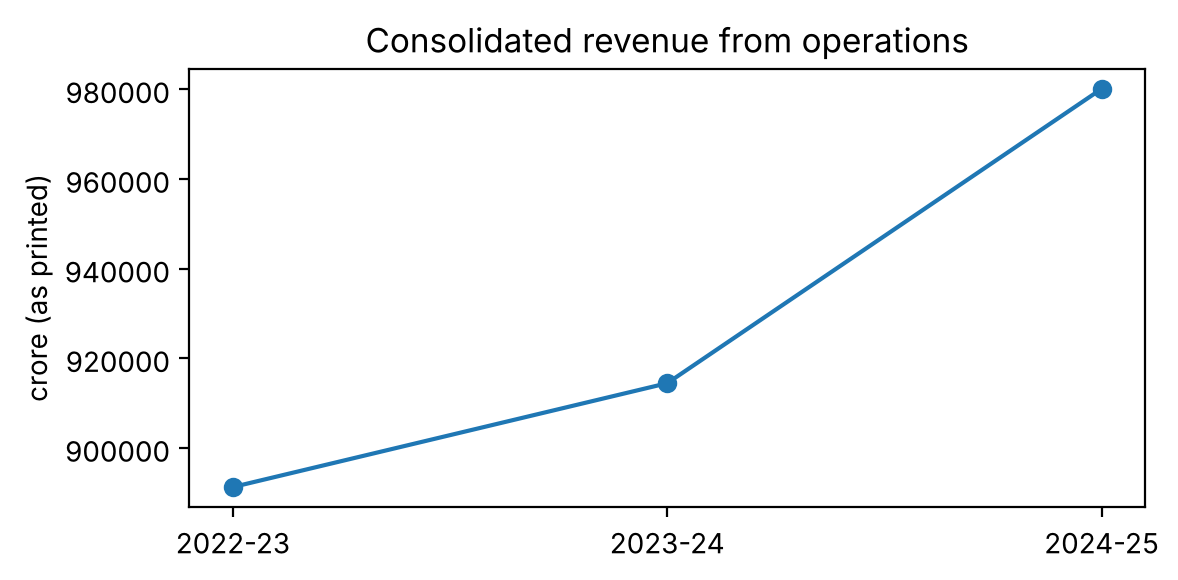

2022-23 891311.0 from RIL-Integrated-Annual-Report-2023-24.pdf
2023-24 914472.0 from RIL-Integrated-Annual-Report-2024-25.pdf
2024-25 980136.0 from RIL-Integrated-Annual-Report-2024-25.pdf


In [9]:
pts = {}
for c in cmp["columns"]:
    v = c["values"].get("revenue_from_operations")
    if v and c["basis"] == "consolidated" and c["period_sort"]:
        pts.setdefault(c["period_label"], (c["period_sort"], float(v["value"]), c["filename"]))
xs = sorted(pts.items(), key=lambda kv: kv[1][0])
plt.figure(figsize=(6, 3))
plt.plot([k for k, _ in xs], [v[1] for _, v in xs], marker="o")
plt.ylabel("crore (as printed)"); plt.title("Consolidated revenue from operations")
plt.tight_layout(); plt.show()
for k, (sk, val, fn) in xs:
    print(k, val, "from", fn)
db.close()

## Interpretation
* Every ratio shows its formula, inputs and the page each input came from; the hand calculation reproduces the engine's result.
* Not-computed ratios are listed with the missing inputs instead of being estimated.
* Charts are drawn only from validated statement values with an explicit basis and unit; the currency stays unstated because the
  documents do not state it in a machine-readable way.

## Common errors and troubleshooting
| Symptom | Cause | Fix |
|---|---|---|
| Ratio missing | An input was not extracted or failed validation | Check Document Analysis; verify or correct values |
| Unexpected period pairing | Fiscal year alignment uses the year in the column header | Check period labels of the inputs |
| Restatement warning | Same metric/period differs between documents | Read both sources: restated figures are common after acquisitions |
| Mixed units in a chart | Different unit statements | Charts group by unit; compare normalised values |

## Practical exercises
1. Compute the current ratio by hand from the stored inputs and compare with the engine.
2. Add a new ratio (e.g. *asset turnover = revenue / total assets*) to `ratios.py` with a test.
3. Compare a standalone and a consolidated value for the same year and read the warning.

## Summary
You used the production ratio engine on real extracted data, checked a result by hand, saw why some ratios are deliberately not
computed, compared reports and visualised ratios and trends.

## Further learning
* CFA Institute — financial ratio analysis overview: https://www.cfainstitute.org/
* FinRAG source: `financial_analytics/ratios.py`, `service.py`, `comparison.py`
* Next: **13 — LoRA fine-tuning**.